# 05b Hand check of 20 CRAS verdicts, and the overall Phase 0.5 gate

**Question.** Do 20 randomly drawn verdicts of notebook 03a (the 35 elements of the CRAS room, no oracle labels) agree with what a person sees in a close-up of the element and the scan points near it? And, with the registration result of 05a and the perturbed-model result of 03b, does the pipeline meet the roadmap's gate, so that it is worth formalising? This notebook reads those results; it does not recompute them.

**Thresholds, fixed before any result.** Verbatim from `docs/roadmap.md` (the same text as 05a's first cell). They are judgement calls, not taken from a standard.

- Registration success per PC2Model sample, after ICP: rotation error <= 2 degrees, translation error <= 5 cm, and scale error <= 1% on scaled samples. At least 6 of the 9 must succeed.
- Perturbed CRAS model: every injected change beyond tolerance gets the right verdict, and at most 10% of untouched elements are falsely flagged shifted or missing.
- Hand check of 20 random real CRAS elements: at least 80% agree with the verdict.
- **If 05 fails:** at most one week of tuning inside 0.5. If it still fails, write it up as a negative result and continue; it motivates the learned registration under Later.

**Decisions made before running** (also judgement calls).

1. *Population.* The 35 room elements of 03a's `verdicts_no_labels.csv`, the realistic run (no oracle labels, no segmentation). 20 are drawn without replacement with `numpy.random.default_rng(SEED)`; `SEED` is in the knobs cell, so the drawn list is the same on every run. The oracle-labels verdict is shown as context only. The roadmap says "random real CRAS elements"; the room is the only slice with verdicts, so 20 of its 35 is more than half of the population, and the 80 % criterion is measured on a sample that is not independent of the room.
2. *Close-up.* One PNG per drawn element, written to `outputs/05b/closeups/<n>_<class>_<GlobalId>.png` and also displayed in this notebook, which is how the close-ups are committed (`outputs/` is gitignored). Two panels. **Left, face-on:** the element's own faces (from the IFC) and every scan point within 10 cm of it, projected along the element's thinnest axis, with the scan points of an element class (wall, ceiling, floor, door, window, stairs) apart from clutter and unassigned points. **Right, section:** a 10 cm thick strip through the middle of the element, seen from the side: the horizontal axis runs along the element, the vertical axis across its thickness, so the model's faces are lines and a scan surface that is not on them shows as a gap. The scan is in the model frame by 03a's refined transform (`outputs/03a/frame.json`).
3. *Judgements.* `notebooks/05b_hand_check.csv` (committed) has one row per drawn element, `n, global_id, ifc_class, name, verdict, judgement, note`. The notebook writes it **only if it is absent**, with `judgement` empty. The author fills `judgement` with one of `OK`, `shifted`, `not confirmed`: what he or she thinks the verdict should be after looking at the close-up. Unknown values raise. Agreement is `judgement == verdict` over the filled rows; the criterion needs all 20 filled and at least 80 % agreement. Until then the hand check is **PENDING**, which is not an error.
4. *Perturbed-model criterion.* From 03b's `scores_no_labels.csv` (the headline) and `scores_oracle_labels.csv` (context). "Beyond tolerance" is relative to the LOA30 tolerance of 15 mm: the two moves of 3 and 10 cm and the three not-built elements are beyond it; the **1 cm move is the within-tolerance control** (it must stay OK, and is reported, but is not part of the criterion). The false-flag rate uses the roadmap's literal count: every untouched element whose verdict is shifted or missing, whether or not it was already shifted on the real model (03b prints the count of newly flagged ones as context).
5. *Registration criterion.* 05a's `success` column: best of five RANSAC seeds picked by ICP fitness (05a's decision 2), at least 6 of 9.
6. *Overall.* Pass only if all three criteria pass ("worth formalising"). A failed criterion is final even while the hand check is pending.

In [1]:
import csv, json, os, resource, time
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection, PolyCollection
import numpy as np

os.environ["OPEN3D_DISABLE_WEB_VISUALIZER"] = "true"  # before the import: skips Open3D's Jupyter web-visualizer banner
import open3d as o3d
from IPython.display import Image, display

from scan_vs_bim.gate import VERDICTS, combine, hand_check_result, perturbed_result, read_hand_check, registration_result, write_hand_check_template
from scan_vs_bim.load import load_ifc_elements

%config InlineBackend.figure_format = 'png'
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 80, "font.size": 8})
o3d.utility.set_verbosity_level(o3d.utility.VerbosityLevel.Error)
T_NOTEBOOK = time.time()

# ---- Every knob of this notebook is in this cell. Re-running gives the same numbers. ------------------------------------------
# Gate thresholds from docs/roadmap.md (judgement calls, not from a standard); see the first cell.
GATE_REG_MIN_SUCCESS = 6        # of the 9 PC2Model samples (05a's criterion; 05a applies 2 deg, 5 cm, 1 % itself)
GATE_REG_ROT_DEG, GATE_REG_TRANS_M, GATE_REG_SCALE_PCT = 2.0, 0.05, 1.0   # only to re-derive 05a's success flags as a check
GATE_MAX_FALSE_SHARE = 0.10     # untouched elements falsely flagged shifted or missing
GATE_N_ELEMENTS, GATE_MIN_AGREE = 20, 0.80   # hand check
TOL_MM = 15.0                   # USIBD LOA30: at most 15 mm at 2 sigma (03a / 03b)

SEED = 0                        # the draw of the 20 elements (default_rng) and the subsampling of plotted points
N_DRAW = GATE_N_ELEMENTS

# Close-up geometry (judgement calls). Lengths in metres.
BAND = 0.10                     # scan points further than this from the element's surface are not shown (03a's BAND)
PAD = BAND                      # the room box is padded by this much when cropping the scan (03a's PAD), so the points are 03a's
STRIP = 0.10                    # half thickness of the section strip (a 20 cm thick slice through the element's middle)
ZOOM_ALONG, ZOOM_ACROSS = 0.9, 0.35   # half extents of the section window: along the element, across it (centred on the element's own faces)
MAX_FACEON_POINTS, MAX_SECTION_POINTS, MAX_FACEON_TRIANGLES = 12_000, 9_000, 20_000   # plotted points per panel: keeps each PNG small

# Scan classes (index = class id in the cache); the ones the model has elements for (the rest is clutter). 03a's lists.
CLASS_NAMES = ["unassigned", "ceiling", "floor", "wall", "door", "window", "desk", "chair", "cabinet", "mobile cabinet",
               "shelf", "vents", "water tank", "bin", "box", "board", "computer", "screen", "printer", "vest", "switch",
               "paper dispenser", "alcohol dispenser", "cable", "phone", "robot", "water kettle", "stairs", "ladder",
               "oil heater", "divider", "hanger", "fan", "water dispenser"]
ELEMENT_SCAN_CLASSES = ("ceiling", "floor", "wall", "door", "window", "stairs")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
NB_DIR = ROOT / "notebooks"
HAND_CSV = NB_DIR / "05b_hand_check.csv"   # committed; written below only if absent
SLICE = NB_DIR / "01_cras_slice.json"
CACHE, IFC = ROOT / "data" / "cras" / "cras_voxel_1cm.npz", ROOT / "data" / "cras" / "craslabbim.ifc"
IN_03A, IN_03B, IN_05A = ROOT / "outputs" / "03a", ROOT / "outputs" / "03b", ROOT / "outputs" / "05a"
OUT = ROOT / "outputs" / "05b"          # gitignored; never write outside outputs/ (except the hand-check CSV)
CLOSEUPS = OUT / "closeups"
CLOSEUPS.mkdir(parents=True, exist_ok=True)


def peak_rss_gb():
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e9  # bytes on macOS


def apply(T, p):
    # Rigid transform T (4x4) applied to points p (n, 3); float32 in, float32 out.
    return (p @ T[:3, :3].T.astype(np.float32) + T[:3, 3].astype(np.float32)).astype(np.float32)


def read(path):
    with open(path, newline="") as f:
        return list(csv.DictReader(f))

## 1. Inputs

05b reads the results of 03a (verdicts, the refined transform), 03b (scores, manifest) and 05a (registration). All of them are in `outputs/`, which is gitignored, so they have to be produced first, in this order (commands in `CLAUDE.md`): `scripts/pick_gate_samples.py` and 05a for the registration, then 03a and 03b. If 03a or 03b is changed, **re-run both before this notebook**: 03b recomputes the real-model baseline itself, and the cell below checks that its baseline equals 03a's verdicts.

In [2]:
needs = {IN_03A / "verdicts_no_labels.csv": "notebooks/03a_compare.ipynb", IN_03A / "verdicts_oracle_labels.csv": "notebooks/03a_compare.ipynb",
         IN_03A / "frame.json": "notebooks/03a_compare.ipynb", IN_03B / "scores_no_labels.csv": "notebooks/03b_perturbed.ipynb",
         IN_03B / "scores_oracle_labels.csv": "notebooks/03b_perturbed.ipynb", IN_03B / "manifest.json": "notebooks/03b_perturbed.ipynb",
         IN_05A / "registration.csv": "notebooks/05a_registration_gate.ipynb", SLICE: "notebooks/01_data.ipynb", CACHE: "scripts/build_cras_cache.py",
         IFC: "scripts/fetch_data.py"}
for p, how in needs.items():
    if not p.exists():
        raise FileNotFoundError(f"{p.relative_to(ROOT)} is missing. Produce it with {how} (commands: CLAUDE.md)")

verdicts = {v: read(IN_03A / f"verdicts_{v}.csv") for v in ("no_labels", "oracle_labels")}
frame = json.loads((IN_03A / "frame.json").read_text())
slice_ = json.loads(SLICE.read_text())
scores = {v: read(IN_03B / f"scores_{v}.csv") for v in ("no_labels", "oracle_labels")}
manifest = json.loads((IN_03B / "manifest.json").read_text())
registration = read(IN_05A / "registration.csv")

# Known answers on the inputs: 35 room elements in the same order in all four tables, and 03b's baseline column is 03a's verdict.
guids = slice_["room"]["element_global_ids"]
assert len(guids) == 35
for name, table in [("03a no labels", verdicts["no_labels"]), ("03a oracle labels", verdicts["oracle_labels"]),
                    ("03b no labels", scores["no_labels"]), ("03b oracle labels", scores["oracle_labels"])]:
    assert sorted(r["global_id"] for r in table) == sorted(guids), f"{name}: not the 35 room elements of 01's slice"
for v in ("no_labels", "oracle_labels"):
    base = {r["global_id"]: r["verdict"] for r in verdicts[v]}
    assert all(r["baseline"] == base[r["global_id"]] for r in scores[v]), f"03b's baseline ({v}) differs from 03a's verdicts: re-run 03a and 03b"
assert len(registration) == 9
for v in ("no_labels", "oracle_labels"):
    print(f"03a verdicts, {v:14s}: " + ", ".join(f"{k} {sum(r['verdict'] == k for r in verdicts[v])}" for k in VERDICTS))
print(f"refined transform from 03a/frame.json: ICP correction {frame['icp_correction']['rotation_deg']:.3f} deg, {frame['icp_correction']['room_centroid_mm']:.1f} mm")
print("inputs consistent: 35 elements everywhere, 03b's baseline equals 03a's verdicts")

03a verdicts, no_labels     : OK 5, shifted 1, not confirmed 29
03a verdicts, oracle_labels : OK 6, shifted 2, not confirmed 27
refined transform from 03a/frame.json: ICP correction 0.112 deg, 6.8 mm
inputs consistent: 35 elements everywhere, 03b's baseline equals 03a's verdicts


## 2. The draw: 20 of the 35 elements

`numpy.random.default_rng(SEED).choice(35, 20, replace=False)`, then sorted into 03a's CSV order. Known answers: the draw is repeatable, has 20 distinct elements of the population, and `n` (1 to 20) numbers them in CSV order. The verdict is the one without oracle labels; the oracle-labels verdict is context.

In [3]:
pop = verdicts["no_labels"]
oracle_verdict = {r["global_id"]: r["verdict"] for r in verdicts["oracle_labels"]}
draw = np.sort(np.random.default_rng(SEED).choice(len(pop), N_DRAW, replace=False))
assert (draw == np.sort(np.random.default_rng(SEED).choice(len(pop), N_DRAW, replace=False))).all(), "the draw is not repeatable"
assert len(set(draw)) == N_DRAW and draw.max() < len(pop)
drawn = [dict(pop[i], n=k + 1, oracle=oracle_verdict[pop[i]["global_id"]]) for k, i in enumerate(draw)]

short = lambda r: r["ifc_class"][3:]
print(f"{'n':>2s}  {'class':18s} {'name':40s} {'verdict':14s} {'(oracle)':14s} {'points':>8s} {'median':>9s}  reason")
for r in drawn:
    med = f"{float(r['median_signed_offset_mm']):6.1f} mm" if r["median_signed_offset_mm"] else "      -"
    print(f"{r['n']:2d}  {short(r):18s} {r['name'][-40:]:40s} {r['verdict']:14s} {r['oracle']:14s} {int(r['point_count']):8,d} {med:>9s}  {r['reason']}")
print(f"\ndrawn verdicts:     " + ", ".join(f"{k} {sum(r['verdict'] == k for r in drawn)}" for k in VERDICTS) +
      "      population: " + ", ".join(f"{k} {sum(r['verdict'] == k for r in pop)}" for k in VERDICTS))
print("drawn classes:      " + ", ".join(f"{c[3:]} {sum(r['ifc_class'] == c for r in drawn)}/{sum(r['ifc_class'] == c for r in pop)}" for c in sorted({r['ifc_class'] for r in pop})) + "  (drawn/population)")

# The judgement file: written only if absent, so the author's entries are never overwritten.
template = [{k: r[k] for k in ("n", "global_id", "ifc_class", "name", "verdict")} | {"judgement": "", "note": ""} for r in drawn]
wrote = write_hand_check_template(HAND_CSV, template)
hand = read_hand_check(HAND_CSV)  # validates the columns and the judgements; raises ValueError on an unknown value
if [(int(h["n"]), h["global_id"]) for h in hand] != [(r["n"], r["global_id"]) for r in drawn]:
    raise ValueError(f"{HAND_CSV.name} holds a different draw than SEED={SEED} gives now (03a's CSV or SEED changed). "
                     "Delete the file to start again, or restore SEED / re-run 03a as it was; nothing was overwritten.")
changed = [h["n"] for h, r in zip(hand, drawn) if h["verdict"] != r["verdict"]]
print(f"\n{HAND_CSV.relative_to(ROOT)}: {'written now (judgement column empty)' if wrote else 'already there, kept as is'}; "
      f"{sum(bool(h['judgement']) for h in hand)} of {len(hand)} judgements filled")
if changed:
    print(f"note: the verdict column of rows n={', '.join(changed)} differs from 03a's current verdict; agreement uses the current verdict")

 n  class              name                                     verdict        (oracle)         points    median  reason
 1  Column             e-Rectangular-Column:150 x 350mm:1164179 not confirmed  not confirmed        78    2.6 mm  too few points
 2  Covering           Compound Ceiling:Forro de gesso:1428995  not confirmed  not confirmed   689,932    5.5 mm  inconsistent offsets
 3  Covering           Compound Ceiling:Forro de gesso:1429616  not confirmed  not confirmed     9,323   -2.1 mm  mostly outside the room box
 4  Covering           Forros 1:Forros 1:1537527                not confirmed  not confirmed     1,538    7.1 mm  mostly outside the room box
 5  Door               0:SDE30 - M15 (M10) x M20 - EI30:1044681 not confirmed  not confirmed    64,569   19.9 mm  inconsistent offsets
 6  WallStandardCase   Basic Wall:(10cm) Drywall:961571         not confirmed  not confirmed   328,138 -102.5 mm  inconsistent offsets
 7  WallStandardCase   Basic Wall:(10cm) Drywall:962256      

## 3. Close-ups

The scan cache is read once in 4M-point chunks (03a's way): transformed with the refined transform, cut to the room box padded by `PAD`, and for each drawn element the points within `BAND` of its surface are kept (distance to the element's own mesh). The cut is 03a's, so every point that gave the verdict is a candidate; 03a assigns each point to the *nearest* of the 35 elements, so a point near two elements (a wall and the floor at their junction) is shown for both here, and `shown` below is not 03a's `point_count`.

Colours: dark blue points are scan points of a class the model has an element for (wall, ceiling, floor, door, window, stairs); orange points are everything else (furniture, unassigned): that is what hides an element from the scanner. The model is the light blue fill (face-on) and the black lines (section).

In [4]:
t = time.time()
elements = {e.global_id: e for e in load_ifc_elements(IFC, only_guids=[r["global_id"] for r in drawn])}
assert set(elements) == {r["global_id"] for r in drawn}

BOX = slice_["room"]["box_model_frame"]
box_lo = np.array([BOX[k] for k in ("xmin", "ymin", "zmin")]); box_hi = np.array([BOX[k] for k in ("xmax", "ymax", "zmax")])
crop_lo, crop_hi = box_lo - PAD, box_hi + PAD
T_REFINED = np.array(frame["refined_scan_to_model_4x4"])

scenes, bounds = {}, {}
for g, e in elements.items():
    sc = o3d.t.geometry.RaycastingScene()
    sc.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(o3d.geometry.TriangleMesh(o3d.utility.Vector3dVector(e.vertices), o3d.utility.Vector3iVector(e.faces))))
    scenes[g], bounds[g] = sc, (e.vertices.min(0) - BAND, e.vertices.max(0) + BAND)

cache = np.load(CACHE)
xyz, cls_all = cache["xyz"], cache["cls"]
n_total, n_crop = len(xyz), 0
found = {g: ([], []) for g in elements}   # per element: points (model frame), scan class
for i in range(0, n_total, 4_000_000):
    p = apply(T_REFINED, xyz[i:i + 4_000_000])
    keep = ((p >= crop_lo) & (p <= crop_hi)).all(1)
    p, c = p[keep], cls_all[i:i + 4_000_000][keep]
    n_crop += len(p)
    for g, (lo, hi) in bounds.items():
        m = np.flatnonzero(((p >= lo) & (p <= hi)).all(1))
        if len(m):
            d = scenes[g].compute_distance(o3d.core.Tensor(np.ascontiguousarray(p[m]))).numpy()
            m = m[d <= BAND]
            found[g][0].append(p[m]); found[g][1].append(c[m])
del xyz, cls_all, cache
PTS = {g: (np.concatenate(a) if a else np.zeros((0, 3), np.float32), np.concatenate(b) if b else np.zeros(0, np.uint8)) for g, (a, b) in found.items()}
assert n_crop > 0
print(f"cache {n_total:,} points -> {n_crop:,} in the padded room box ({time.time() - t:.0f} s); peak RSS {peak_rss_gb():.2f} GB")
print(f"{'n':>2s} {'class':18s} {'shown (<= 10 cm from the element)':>34s} {'03a point_count':>16s}")
for r in drawn:
    print(f"{r['n']:2d} {short(r):18s} {len(PTS[r['global_id']][0]):34,d} {int(r['point_count']):16,d}")

cache 20,404,814 points -> 4,064,703 in the padded room box (17 s); peak RSS 1.53 GB
 n class               shown (<= 10 cm from the element)  03a point_count
 1 Column                                             78               78
 2 Covering                                      752,231          689,932
 3 Covering                                       33,515            9,323
 4 Covering                                        6,922            1,538
 5 Door                                           88,091           64,569
 6 WallStandardCase                              382,469          328,138
 7 WallStandardCase                               19,957           11,750
 8 WallStandardCase                              432,876          360,985
 9 WallStandardCase                               13,742            3,255
10 WallStandardCase                               10,518            6,696
11 WallStandardCase                               40,813           29,000
12 Window                  

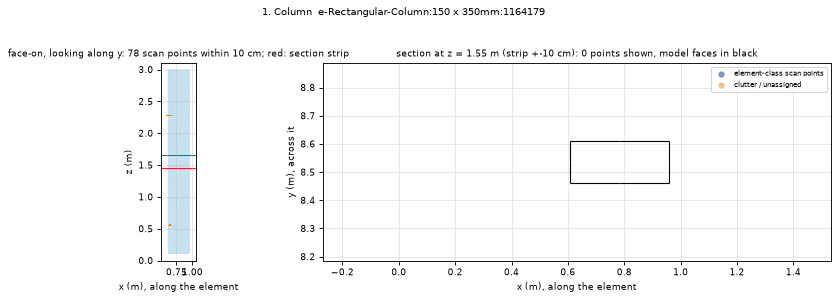

1. IfcColumn  M_Concrete-Rectangular-Column:150 x 350mm:1164179  GlobalId 054HMVvnL1EOSZl$bniLeG
   verdict not confirmed (with oracle labels: not confirmed); 78 points (03a), median signed offset 2.6 mm; reason: too few points   [25 kB]



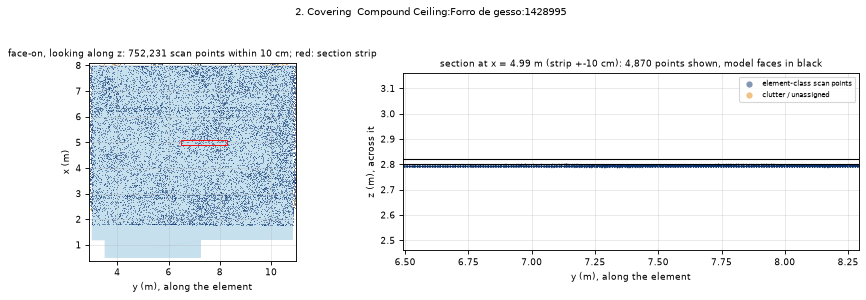

2. IfcCovering  Compound Ceiling:Forro de gesso:1428995  GlobalId 2unE$VYSL2OPIL$6LYYccT
   verdict not confirmed (with oracle labels: not confirmed); 689,932 points (03a), median signed offset 5.5 mm; reason: inconsistent offsets   [52 kB]



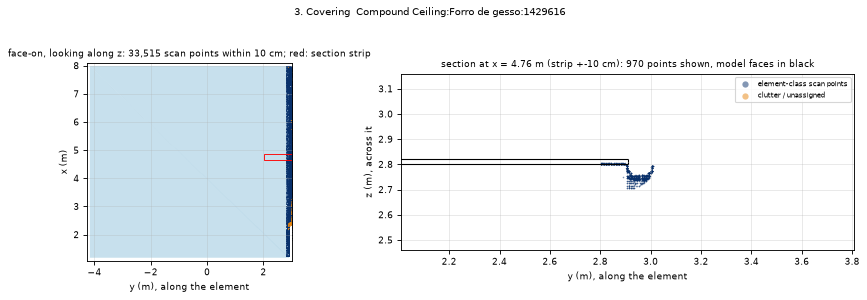

3. IfcCovering  Compound Ceiling:Forro de gesso:1429616  GlobalId 2unE$VYSL2OPIL$6LYYdVk
   verdict not confirmed (with oracle labels: not confirmed); 9,323 points (03a), median signed offset -2.1 mm; reason: mostly outside the room box   [30 kB]



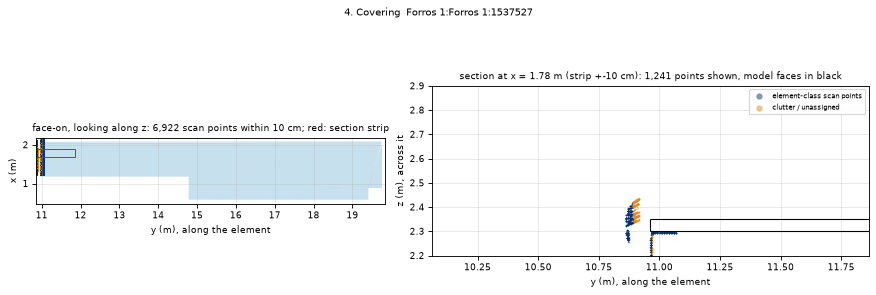

4. IfcCovering  Forros 1:Forros 1:1537527  GlobalId 33gtcvddH7cec8$WOT4fKs
   verdict not confirmed (with oracle labels: not confirmed); 1,538 points (03a), median signed offset 7.1 mm; reason: mostly outside the room box   [29 kB]



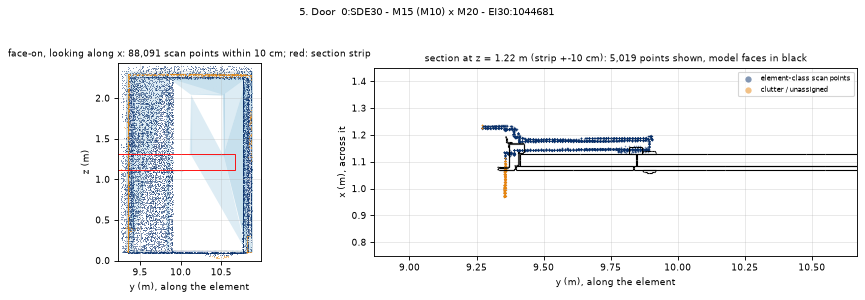

5. IfcDoor  Doors_Door-sets_Swedoor_JELD-WEN_Exterior_Steel_4210_GS1T_Unequal_Double_40:SDE30 - M15 (M10) x M20 - EI30:1044681  GlobalId 0WU0DUvgT6tu4IXFc9kNX5
   verdict not confirmed (with oracle labels: not confirmed); 64,569 points (03a), median signed offset 19.9 mm; reason: inconsistent offsets   [63 kB]



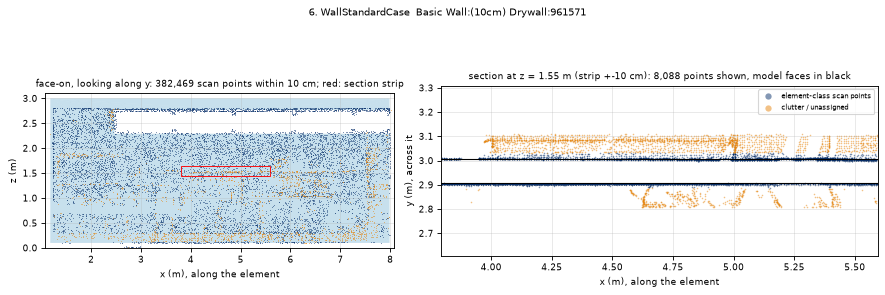

6. IfcWallStandardCase  Basic Wall:(10cm) Drywall:961571  GlobalId 1gsZ4XbYD0qRhfvwOUEI1z
   verdict not confirmed (with oracle labels: not confirmed); 328,138 points (03a), median signed offset -102.5 mm; reason: inconsistent offsets   [79 kB]



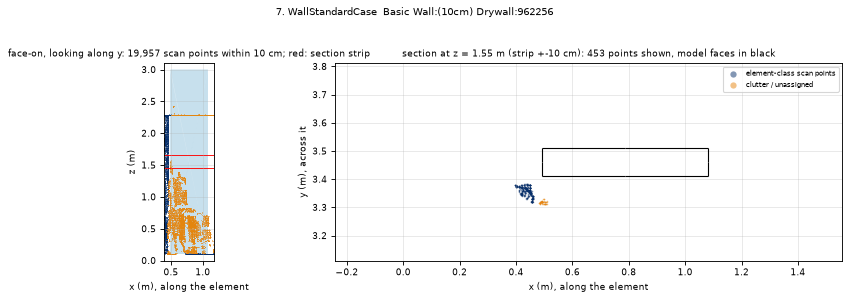

7. IfcWallStandardCase  Basic Wall:(10cm) Drywall:962256  GlobalId 1gsZ4XbYD0qRhfvwOUEIAE
   verdict not confirmed (with oracle labels: not confirmed); 11,750 points (03a), median signed offset 5.1 mm; reason: inconsistent offsets   [34 kB]



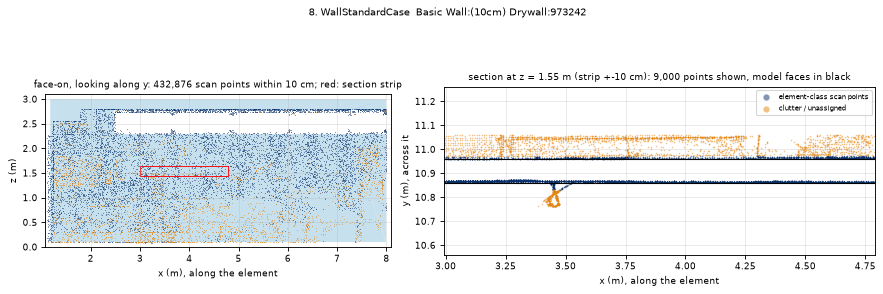

8. IfcWallStandardCase  Basic Wall:(10cm) Drywall:973242  GlobalId 3qeiF73TD1uOeHIcNGcTy8
   verdict not confirmed (with oracle labels: not confirmed); 360,985 points (03a), median signed offset -7.4 mm; reason: inconsistent offsets   [77 kB]



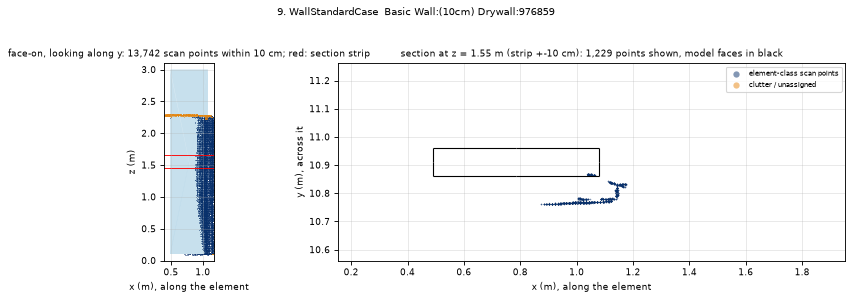

9. IfcWallStandardCase  Basic Wall:(10cm) Drywall:976859  GlobalId 3qeiF73TD1uOeHIcNGcU5f
   verdict not confirmed (with oracle labels: not confirmed); 3,255 points (03a), median signed offset 47.6 mm; reason: inconsistent offsets   [34 kB]



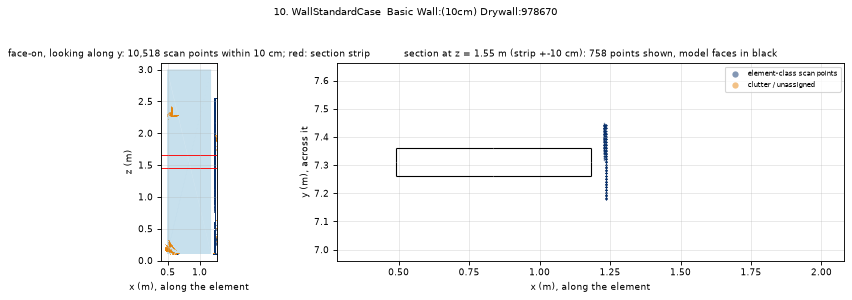

10. IfcWallStandardCase  Basic Wall:(10cm) Drywall:978670  GlobalId 3qeiF73TD1uOeHIcNGcUXS
   verdict not confirmed (with oracle labels: not confirmed); 6,696 points (03a), median signed offset 55.0 mm; reason: inconsistent offsets   [28 kB]



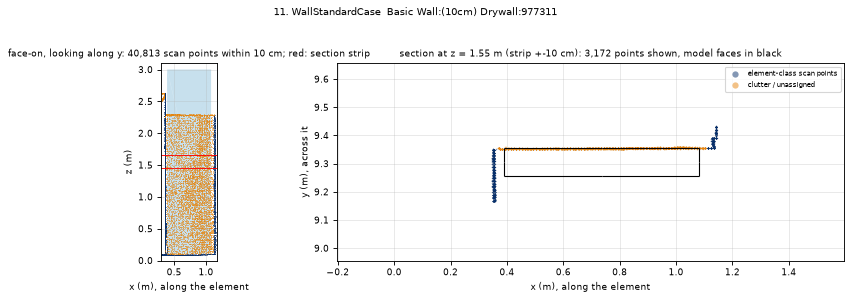

11. IfcWallStandardCase  Basic Wall:(10cm) Drywall:977311  GlobalId 3qeiF73TD1uOeHIcNGcUyj
   verdict not confirmed (with oracle labels: not confirmed); 29,000 points (03a), median signed offset -2.6 mm; reason: inconsistent offsets   [41 kB]



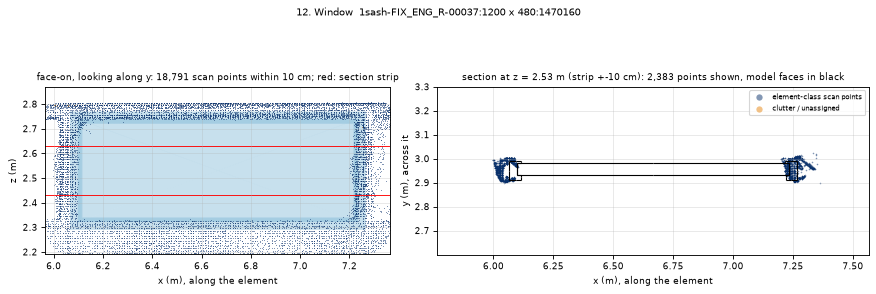

12. IfcWindow  Aluprof_MB-86-ST_E_Alu_Window-1sash-FIX_ENG_R-00037:1200 x 480:1470160  GlobalId 1L1ux2$dP8WO2wsydYGc16
   verdict OK (with oracle labels: OK); 5,875 points (03a), median signed offset -0.2 mm; reason: none   [53 kB]



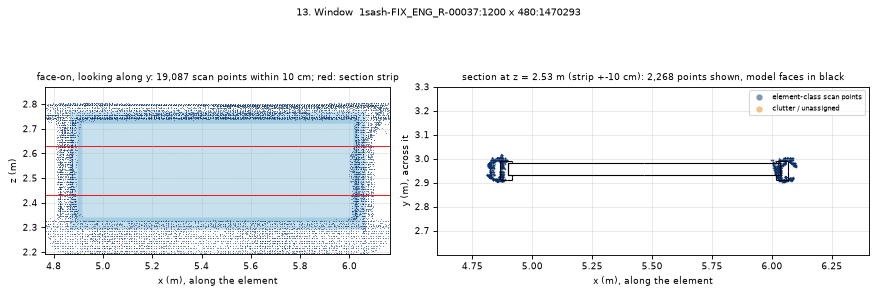

13. IfcWindow  Aluprof_MB-86-ST_E_Alu_Window-1sash-FIX_ENG_R-00037:1200 x 480:1470293  GlobalId 1L1ux2$dP8WO2wsydYGc73
   verdict OK (with oracle labels: OK); 6,587 points (03a), median signed offset -0.2 mm; reason: none   [50 kB]



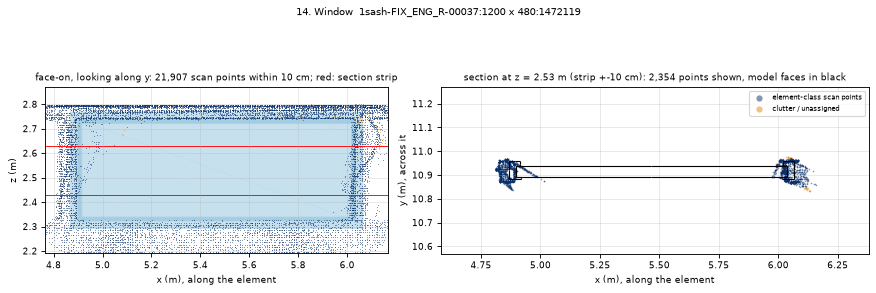

14. IfcWindow  Aluprof_MB-86-ST_E_Alu_Window-1sash-FIX_ENG_R-00037:1200 x 480:1472119  GlobalId 1L1ux2$dP8WO2wsydYGdZX
   verdict OK (with oracle labels: OK); 6,656 points (03a), median signed offset 0.1 mm; reason: none   [54 kB]



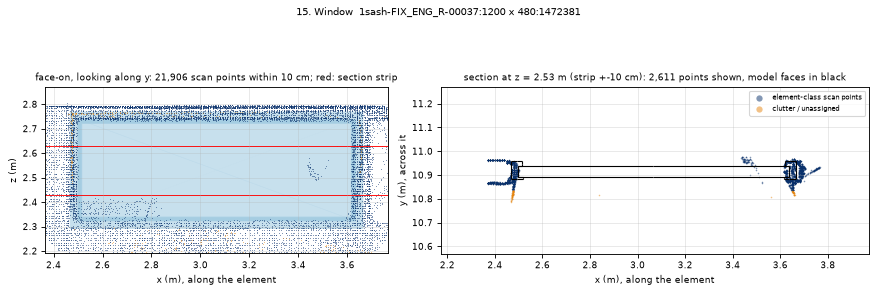

15. IfcWindow  Aluprof_MB-86-ST_E_Alu_Window-1sash-FIX_ENG_R-00037:1200 x 480:1472381  GlobalId 1L1ux2$dP8WO2wsydYGddh
   verdict not confirmed (with oracle labels: not confirmed); 7,952 points (03a), median signed offset -1.7 mm; reason: inconsistent offsets   [55 kB]



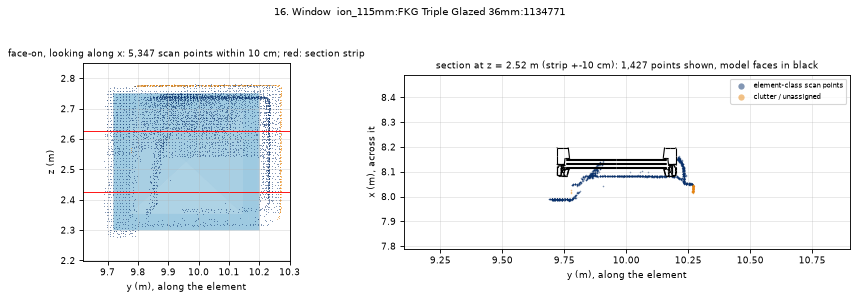

16. IfcWindow  Window-Westcoas_Windows-FKG-Fixed-Frame_Option_115mm:FKG Triple Glazed 36mm:1134771  GlobalId 1clZEeY_LECBal6NIv_ikZ
   verdict not confirmed (with oracle labels: not confirmed); 2,697 points (03a), median signed offset 8.9 mm; reason: inconsistent offsets   [46 kB]



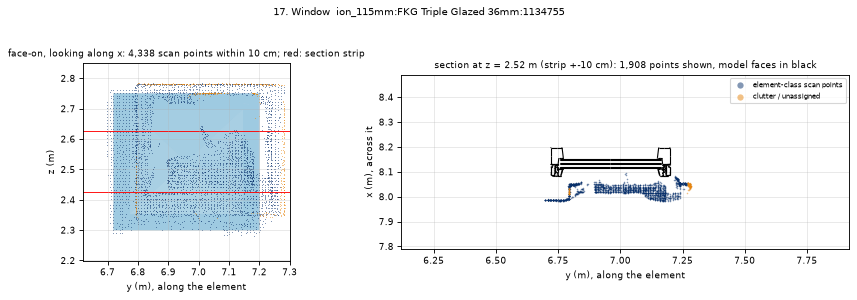

17. IfcWindow  Window-Westcoas_Windows-FKG-Fixed-Frame_Option_115mm:FKG Triple Glazed 36mm:1134755  GlobalId 1clZEeY_LECBal6NIv_ikp
   verdict not confirmed (with oracle labels: not confirmed); 1,965 points (03a), median signed offset 66.7 mm; reason: too few points   [48 kB]



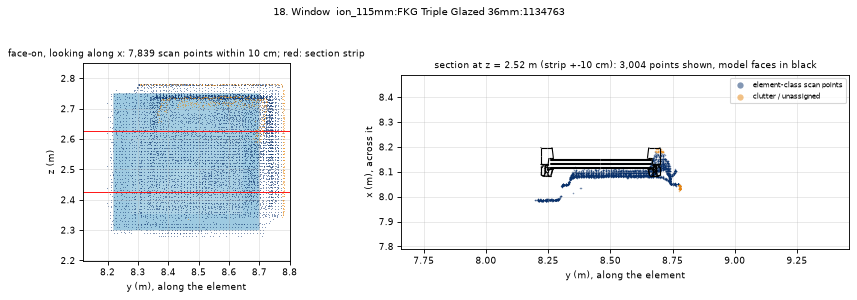

18. IfcWindow  Window-Westcoas_Windows-FKG-Fixed-Frame_Option_115mm:FKG Triple Glazed 36mm:1134763  GlobalId 1clZEeY_LECBal6NIv_ikx
   verdict not confirmed (with oracle labels: not confirmed); 4,800 points (03a), median signed offset 16.1 mm; reason: inconsistent offsets   [52 kB]



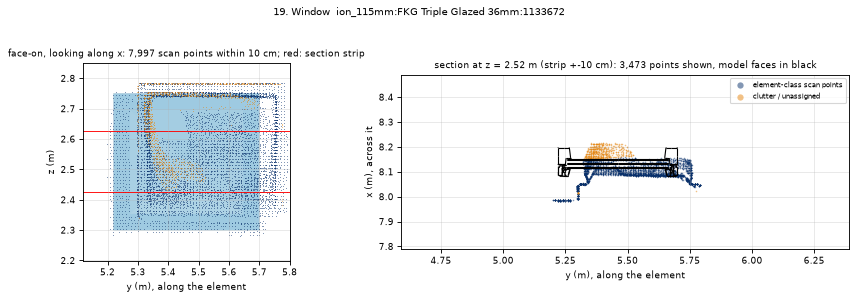

19. IfcWindow  Window-Westcoas_Windows-FKG-Fixed-Frame_Option_115mm:FKG Triple Glazed 36mm:1133672  GlobalId 1clZEeY_LECBal6NIv_jTu
   verdict not confirmed (with oracle labels: not confirmed); 5,489 points (03a), median signed offset 9.8 mm; reason: inconsistent offsets   [55 kB]



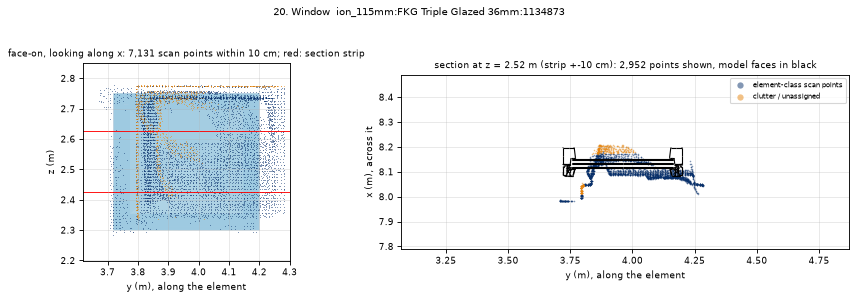

20. IfcWindow  Window-Westcoas_Windows-FKG-Fixed-Frame_Option_115mm:FKG Triple Glazed 36mm:1134873  GlobalId 3iJGmd4gX4uwx4ku7SqaZ_
   verdict not confirmed (with oracle labels: not confirmed); 5,019 points (03a), median signed offset 13.1 mm; reason: inconsistent offsets   [53 kB]

20 close-ups, 48 kB on average (largest 79 kB); peak RSS 1.53 GB


In [5]:
ELEMENT_CLASS_IDS = [CLASS_NAMES.index(n) for n in ELEMENT_SCAN_CLASSES]
AXIS = "xyz"


def view_axes(vertices):
    # t: the element's thinnest bounding-box axis (across it). Along it: for a vertical element (t horizontal) l is the other horizontal
    # axis and w is z, so height is vertical in the face-on view; for a flat one (t is z) l is the longer of x, y and w the other.
    ext = np.ptp(vertices, axis=0)
    t = int(np.argmin(ext))
    rest = [i for i in range(3) if i != t]
    if t != 2:
        return [i for i in rest if i != 2][0], 2, t
    l = max(rest, key=lambda i: ext[i])
    return l, [i for i in rest if i != l][0], t


def section(vertices, faces, axis, value):
    # Line segments where the plane axis == value cuts the triangles: (n, 2, 2), end points in the other two axes (in index order).
    tri = vertices[faces]
    s = tri[:, :, axis] - value
    keep_axes = [i for i in range(3) if i != axis]
    S = np.full((len(tri), 2, 2), np.nan)
    count = np.zeros(len(tri), int)
    for i, j in ((0, 1), (1, 2), (2, 0)):
        idx = np.where(s[:, i] * s[:, j] < 0)[0]
        f = s[idx, i] / (s[idx, i] - s[idx, j])
        S[idx, count[idx]] = tri[idx, i][:, keep_axes] + f[:, None] * (tri[idx, j][:, keep_axes] - tri[idx, i][:, keep_axes])
        count[idx] += 1
    return S[count == 2]


def closeup(r, path):
    g = r["global_id"]
    e, (P, cls) = elements[g], PTS[g]
    l, w, t = view_axes(e.vertices)
    lo, hi = e.vertices.min(0), e.vertices.max(0)
    centre = (lo + hi) / 2
    c_l, c_w = (float(np.median(P[:, l])), float(np.median(P[:, w]))) if len(P) else (centre[l], centre[w])
    if t != 2:
        c_w = centre[w]   # a vertical element: the section at its mid-height (the median of nearby points can lie in the wall above a window)
    c_l, c_w = np.clip(c_l, lo[l], hi[l]), np.clip(c_w, lo[w], hi[w])   # a section through the element, not through clutter next to it
    rs = np.random.default_rng(SEED)
    is_el = np.isin(cls, ELEMENT_CLASS_IDS)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.7), gridspec_kw=dict(width_ratios=[1, 1.25]))
    # left: face-on (axes l, w)
    tri = e.vertices[e.faces][:, :, [l, w]]
    if len(tri) > MAX_FACEON_TRIANGLES:
        tri = tri[rs.choice(len(tri), MAX_FACEON_TRIANGLES, replace=False)]
    ax1.add_collection(PolyCollection(tri, facecolor="#9ecae1", edgecolor="none", alpha=0.35, rasterized=True))
    k = rs.choice(len(P), min(len(P), MAX_FACEON_POINTS), replace=False) if len(P) else np.zeros(0, int)
    for sel, colour in ((is_el[k], "#08306b"), (~is_el[k], "#e6850e")):
        ax1.scatter(P[k][sel, l], P[k][sel, w], s=0.6, c=colour, alpha=0.5, linewidths=0, rasterized=True)
    ax1.add_patch(plt.Rectangle((c_l - ZOOM_ALONG, c_w - STRIP), 2 * ZOOM_ALONG, 2 * STRIP, fill=False, ec="r", lw=0.8))
    ax1.set_xlim(lo[l] - BAND, hi[l] + BAND); ax1.set_ylim(lo[w] - BAND, hi[w] + BAND)
    ax1.set_aspect("equal"); ax1.grid(alpha=0.3)
    ax1.set_xlabel(f"{AXIS[l]} (m), along the element"); ax1.set_ylabel(f"{AXIS[w]} (m)")
    ax1.set_title(f"face-on, looking along {AXIS[t]}: {len(P):,} scan points within 10 cm; red: section strip", fontsize=8)
    # right: section (axes l, t) through the strip |w - c_w| <= STRIP
    m = (np.abs(P[:, w] - c_w) <= STRIP) & (np.abs(P[:, l] - c_l) <= ZOOM_ALONG) & (np.abs(P[:, t] - centre[t]) <= ZOOM_ACROSS)
    idx = np.flatnonzero(m)
    idx = rs.choice(idx, min(len(idx), MAX_SECTION_POINTS), replace=False) if len(idx) else idx
    for sel, colour, label in ((is_el[idx], "#08306b", "element-class scan points"), (~is_el[idx], "#e6850e", "clutter / unassigned")):
        ax2.scatter(P[idx][sel, l], P[idx][sel, t], s=2, c=colour, alpha=0.5, linewidths=0, rasterized=True, label=label)
    keep_axes = [a for a in range(3) if a != w]
    seg = section(e.vertices, e.faces, w, c_w)[:, :, [keep_axes.index(l), keep_axes.index(t)]]
    ax2.add_collection(LineCollection(seg, colors="k", linewidths=1.0))
    ax2.set_xlim(c_l - ZOOM_ALONG, c_l + ZOOM_ALONG); ax2.set_ylim(centre[t] - ZOOM_ACROSS, centre[t] + ZOOM_ACROSS)
    ax2.set_aspect("equal"); ax2.grid(alpha=0.3)
    ax2.set_xlabel(f"{AXIS[l]} (m), along the element"); ax2.set_ylabel(f"{AXIS[t]} (m), across it")
    ax2.set_title(f"section at {AXIS[w]} = {c_w:.2f} m (strip +-{STRIP * 100:.0f} cm): {len(idx):,} points shown, model faces in black", fontsize=8)
    ax2.legend(loc="upper right", fontsize=6.5, markerscale=4)
    fig.suptitle(f"{r['n']}. {short(r)}  {r['name'][-40:]}", fontsize=9, y=0.995)
    plt.tight_layout(rect=(0, 0, 1, 0.955))
    fig.savefig(path, dpi=80, bbox_inches="tight")  # about 880 px wide
    plt.close(fig)


for r in drawn:
    path = CLOSEUPS / f"{r['n']:02d}_{short(r)}_{r['global_id']}.png"
    closeup(r, path)
    display(Image(filename=str(path)))
    med = f"{float(r['median_signed_offset_mm']):.1f} mm" if r["median_signed_offset_mm"] else "none (no points)"
    print(f"{r['n']}. {r['ifc_class']}  {r['name']}  GlobalId {r['global_id']}\n"
          f"   verdict {r['verdict']} (with oracle labels: {r['oracle']}); {int(r['point_count']):,} points (03a), median signed offset {med}; "
          f"reason: {r['reason'] or 'none'}   [{path.stat().st_size / 1000:.0f} kB]\n")
sizes = [p.stat().st_size for p in CLOSEUPS.glob("*.png")]
assert len(list(CLOSEUPS.glob("*.png"))) >= N_DRAW and max(sizes) < 400_000, "close-up PNGs missing or large"
print(f"{N_DRAW} close-ups, {np.mean(sizes) / 1000:.0f} kB on average (largest {max(sizes) / 1000:.0f} kB); peak RSS {peak_rss_gb():.2f} GB")

## 4. Hand check

The judgements are in `notebooks/05b_hand_check.csv`, filled in by the author from the close-ups above. `judgement` is what the element's verdict should be (`OK`, `shifted`, `not confirmed`); `note` is free text. Agreement is `judgement == verdict` over the filled rows. The criterion is at least 80 % agreement with all 20 filled; until then the result is PENDING.

In [6]:
drawn_by_id = {r["global_id"]: r for r in drawn}
for h in hand:  # score against 03a's current verdict
    h["verdict"] = drawn_by_id[h["global_id"]]["verdict"]
HAND = hand_check_result(hand, n_required=GATE_N_ELEMENTS, min_share=GATE_MIN_AGREE)
print(f"{'n':>2s}  {'class':18s} {'verdict':14s} {'judgement':14s} {'agree':>5s}  note")
for h in hand:
    print(f"{h['n']:>2s}  {h['ifc_class'][3:]:18s} {h['verdict']:14s} {h['judgement'] or '-':14s} {('yes' if h['judgement'] == h['verdict'] else 'NO') if h['judgement'] else '':>5s}  {h['note']}")
share = "n/a" if HAND["share"] is None else f"{HAND['share']:.0%}"
print(f"\nfilled {HAND['n_filled']} of {len(hand)}; agree {HAND['n_agree']} of {HAND['n_filled']} ({share}); needed: all {GATE_N_ELEMENTS} filled and >= {GATE_MIN_AGREE:.0%}")
print(f"hand check: {HAND['status']}")

 n  class              verdict        judgement      agree  note
 1  Column             not confirmed  -                     
 2  Covering           not confirmed  -                     
 3  Covering           not confirmed  -                     
 4  Covering           not confirmed  -                     
 5  Door               not confirmed  -                     
 6  WallStandardCase   not confirmed  -                     
 7  WallStandardCase   not confirmed  -                     
 8  WallStandardCase   not confirmed  -                     
 9  WallStandardCase   not confirmed  -                     
10  WallStandardCase   not confirmed  -                     
11  WallStandardCase   not confirmed  -                     
12  Window             OK             -                     
13  Window             OK             -                     
14  Window             OK             -                     
15  Window             not confirmed  -                     
16  Window          

## 5. Perturbed-model criterion (from 03b)

Read from 03b's score tables, one row per room element. Known answers first: every row's `expected` follows from the rule (a move within the 15 mm tolerance expects OK, a larger move expects shifted, an element not built expects not confirmed), the injected offsets equal the manifest's, and the untouched rows are the elements the manifest does not list.

In [7]:
changes = {c["global_id"]: c for c in manifest["changes"]}
EXPECT = {"not_built": "not confirmed"}
for v, rows in scores.items():
    assert {r["global_id"] for r in rows if r["change"]} == set(changes), f"{v}: the changed rows are not the manifest's changes"
    for r in rows:
        c = changes.get(r["global_id"])
        if not c:
            assert r["expected"] == "" and r["change"] == ""
            continue
        assert r["change"] == c["change"]
        if c["change"] == "moved":
            mm = float(np.linalg.norm(c["offset_m"])) * 1000
            assert abs(float(r["injected_offset_mm"]) - mm) < 0.5
            assert r["expected"] == ("OK" if mm <= TOL_MM else "shifted")
        else:
            assert r["expected"] == EXPECT["not_built"]

PERT = {v: perturbed_result(rows, TOL_MM, GATE_MAX_FALSE_SHARE) for v, rows in scores.items()}
for v, rows in scores.items():
    P_ = PERT[v]
    print(f"=== {v} ===" + ("   <- the criterion's run (no oracle labels)" if v == "no_labels" else "   (context)"))
    print(f"{'change':10s} {'element':30s} {'injected':>9s} {'beyond tol.':>12s} {'expected':>14s} {'actual':>14s}  right")
    for r in rows:
        if r["change"]:
            beyond = r["change"] == "not_built" or abs(float(r["injected_offset_mm"])) > TOL_MM
            inj = f"{float(r['injected_offset_mm']):.0f} mm" if r["injected_offset_mm"] != "" else "-"
            print(f"{r['change']:10s} {(short(r) + ' ' + r['name'][-14:]):30s} {inj:>9s} {'yes' if beyond else 'no (control)':>12s} {r['expected']:>14s} {r['actual']:>14s}  {'yes' if r['actual'] == r['expected'] else 'NO'}")
    flagged = [r for r in rows if not r["change"] and r["actual"] in ("shifted", "missing")]
    for r in flagged:
        print(f"  untouched, flagged {r['actual']}: {short(r)} {r['name'][-24:]} (baseline {r['baseline']}, median {float(r['median_signed_offset_mm']):.1f} mm)")
    print(f"(i)  changes beyond tolerance with the right verdict: {P_['n_beyond_right']} of {P_['n_beyond']}  -> {'ok' if P_['changes_ok'] else 'FAIL'}"
          f"   (control, within tolerance: {P_['n_control_right']} of {P_['n_control']} right; counting it, {P_['n_beyond_right'] + P_['n_control_right']} of {P_['n_beyond'] + P_['n_control']}, the figure 03b prints)")
    print(f"(ii) untouched elements flagged shifted or missing: {P_['n_false']} of {P_['n_untouched']} = {P_['share_false']:.1%}  (at most {GATE_MAX_FALSE_SHARE:.0%})  -> {'ok' if P_['false_ok'] else 'FAIL'}")
    print(f"perturbed-model criterion, {v}: {P_['status']}\n")

=== no_labels ===   <- the criterion's run (no oracle labels)
change     element                         injected  beyond tol.       expected         actual  right
not_built  Column  350mm:1164179                  -          yes  not confirmed  not confirmed  yes
not_built  Door - EI30:1044681                    -          yes  not confirmed  not confirmed  yes
moved      WallStandardCase Drywall:961571     10 mm no (control)             OK  not confirmed  NO
moved      WallStandardCase Drywall:973242     30 mm          yes        shifted  not confirmed  NO
moved      WallStandardCase Drywall:978670    100 mm          yes        shifted  not confirmed  NO
not_built  WallStandardCase Drywall:979093         -          yes  not confirmed  not confirmed  yes
  untouched, flagged shifted: WallStandardCase ll:(10cm) Drywall:976859 (baseline not confirmed, median 92.9 mm)
(i)  changes beyond tolerance with the right verdict: 3 of 5  -> FAIL   (control, within tolerance: 0 of 1 right; counting

## 6. Registration criterion (from 05a)

05a's `registration.csv`, one row per PC2Model sample: `success` is 05a's flag (best of five RANSAC seeds picked by ICP fitness; rotation error <= 2 degrees, centroid error <= 5 cm, scale error <= 1 % on scaled samples). The cell re-derives each flag from the three errors as a check, then counts.

In [8]:
print(f"{'sample':58s} {'scaled':>6s} {'rot deg':>8s} {'centroid m':>11s} {'scale err %':>12s} {'success':>8s}")
for r in registration:
    scaled = r["scaled"] == "True"
    derived = float(r["rot_deg"]) <= GATE_REG_ROT_DEG and float(r["centroid_m"]) <= GATE_REG_TRANS_M and (not scaled or float(r["scale_err_pct"]) <= GATE_REG_SCALE_PCT)
    assert derived == (r["success"] == "True"), f"{r['sample']}: success flag differs from the thresholds"
    print(f"{Path(r['sample']).name[:58]:58s} {'yes' if scaled else 'no':>6s} {float(r['rot_deg']):8.2f} {float(r['centroid_m']):11.3f} {float(r['scale_err_pct']):12.2f} {r['success']:>8s}")
REG = registration_result(registration, GATE_REG_MIN_SUCCESS)
by_cat = {c: sum(r["success"] == "True" for r in registration if r["category"] == c) for c in dict.fromkeys(r["category"] for r in registration)}
print(f"\nsuccessful: {REG['n_success']} of {REG['n_total']} (needed {GATE_REG_MIN_SUCCESS}); by category: " + ", ".join(f"{c} {n}/3" for c, n in by_cat.items()))
print(f"registration criterion: {REG['status']}")

sample                                                     scaled  rot deg  centroid m  scale err %  success
house_23-sketchfab                                            yes     0.23       0.070         3.90    False
house_13-sketchfab                                             no     0.02       0.002         0.00     True
house_18-sketchfab                                             no     0.54       0.041         0.00     True
indoor_modelling_4-ISPRS_indoor_modelling-UoM                 yes     0.05       0.024         1.55    False
indoor_modelling_3-ISPRS_indoor_modelling-UVigo                no     0.09       0.023         0.00     True
indoor_modelling_0-ISPRS_indoor_modelling-TUBS1               yes     0.13       0.171         5.29    False
real-indoor_modelling_1-ISPRS_indoor_modelling-TUBS2          yes     0.18       0.221         7.40    False
real-indoor_modelling_3-ISPRS_indoor_modelling-UVigo           no     0.33       0.139         0.00    False
real-indoor_modelli

## 7. The gate

Pass or fail per criterion, and overall. The perturbed-model line is the no-labels run (the realistic one); the oracle-labels run is in section 5 for context.

In [9]:
P_ = PERT["no_labels"]
parts = {"registration (05a)": REG["status"], "perturbed model (03b, no labels)": P_["status"], "hand check (05b)": HAND["status"]}
OVERALL = combine(list(parts.values()))
print(f"registration: {REG['n_success']} of {REG['n_total']} samples succeed (needed {GATE_REG_MIN_SUCCESS})  -> {REG['status']}")
print(f"perturbed model: {P_['n_beyond_right']} of {P_['n_beyond']} changes beyond tolerance right; {P_['n_false']} of {P_['n_untouched']} untouched falsely flagged "
      f"({P_['share_false']:.1%}, at most {GATE_MAX_FALSE_SHARE:.0%})  -> {P_['status']}")
print(f"hand check: {HAND['n_agree']} of {HAND['n_filled']} filled agree" + ("" if HAND["share"] is None else f" ({HAND['share']:.0%})") +
      f"; needed all {GATE_N_ELEMENTS} filled and >= {GATE_MIN_AGREE:.0%}  -> {HAND['status']}")
decided = [k for k, v in parts.items() if v == "FAIL"]
pending = [k for k, v in parts.items() if v == "PENDING"]
print(f"\nOVERALL: {OVERALL}" + (f"  (decided by: {', '.join(decided)}" + (f"; still pending, and it cannot change this: {', '.join(pending)})" if pending else ")") if decided else
                                 (f"  (waiting for: {', '.join(pending)})" if pending else "  (all three criteria pass: worth formalising)")))
if OVERALL == "FAIL":
    print("\nThe roadmap allows at most one week of tuning inside Phase 0.5. If the gate still fails after that, the result is written up as a negative "
          "result and the project continues; it motivates the learned registration under Later.")
OUT.mkdir(parents=True, exist_ok=True)
(OUT / "gate.json").write_text(json.dumps({"overall": OVERALL, "registration": REG, "perturbed_no_labels": PERT["no_labels"], "perturbed_oracle_labels": PERT["oracle_labels"],
                                           "hand_check": HAND, "seed": SEED, "drawn": [r["global_id"] for r in drawn]}, indent=1))

registration: 4 of 9 samples succeed (needed 6)  -> FAIL
perturbed model: 3 of 5 changes beyond tolerance right; 1 of 29 untouched falsely flagged (3.4%, at most 10%)  -> FAIL
hand check: 0 of 0 filled agree; needed all 20 filled and >= 80%  -> PENDING

OVERALL: FAIL  (decided by: registration (05a), perturbed model (03b, no labels); still pending, and it cannot change this: hand check (05b))

The roadmap allows at most one week of tuning inside Phase 0.5. If the gate still fails after that, the result is written up as a negative result and the project continues; it motivates the learned registration under Later.


1393

In [10]:
print(f"peak RSS {peak_rss_gb():.2f} GB, notebook run {time.time() - T_NOTEBOOK:.0f} s")

peak RSS 1.53 GB, notebook run 21 s


## Answer

**The gate fails already, on two of its three criteria; the hand check is still to be filled in and cannot change that.** Overall: **FAIL**, so by the roadmap the pipeline is not yet worth formalising as it stands. The roadmap then allows at most one week of tuning inside Phase 0.5, and a negative-result write-up if the gate still fails after it.

| criterion | result | status |
|---|---|---|
| Registration (05a), >= 6 of 9 samples succeed | **4 of 9** (house 2 of 3, simulated indoor 1 of 3, real indoor 1 of 3) | **FAIL** |
| Perturbed model (03b, no labels), every change beyond tolerance right | **3 of 5** right (the not-built column, door and wall); both moves beyond tolerance (3 and 10 cm) come out not confirmed, not shifted | **FAIL** |
| Perturbed model, at most 10 % of untouched falsely flagged shifted or missing | **1 of 29 = 3.4 %** (`Drywall:976859`, not confirmed on the real model, shifted at +93 mm after the perturbation) | ok |
| Hand check, all 20 filled and >= 80 % agree | **0 of 20 filled** | **PENDING** |

**Perturbed model, in detail.** The 1 cm control (it must stay OK, within the 15 mm tolerance) comes out not confirmed in both runs and is not part of the criterion; counting it, the totals are 3 of 6 without labels and 2 of 6 with oracle labels, the figures 03b prints and issue #11 reports. With oracle labels the not-built wall `Drywall:979093` also comes out shifted (it was already shifted on the real model), so 2 of 5 are right, and 2 of 29 untouched elements are falsely flagged (6.9 %): the false-flag clause passes in both runs, the changes clause fails in both. The failure is the real-model baseline's: only 1 of the 35 elements is shifted and 5 are OK without labels, so there is little for a perturbation to turn into the right verdict (issues #17 and #18).

**Registration, in detail.** Best of five RANSAC seeds picked by ICP fitness. All four scaled samples fail the 1 % scale criterion (scale errors 1.5, 3.9, 5.3 and 7.4 %; their centroid errors are 2.4, 7.0, 17 and 22 cm). Of the five unscaled samples four succeed; the failure is the real UVigo scan (rotation 0.33 degrees, but centroid error 13.9 cm). 05a has the table and the discussion.

**The draw (SEED 0).** 20 of the 35 elements: 1 column, 3 coverings, 1 door, 6 walls, 9 windows and no slab. By verdict (no labels): **17 not confirmed, 3 OK, 0 shifted** (population: 29, 5, 1). The oracle-labels verdict is the same for all 20. Two things to keep in mind while judging. First, 17 of 20 verdicts are not confirmed, which is also the default verdict of the logic (anything that is not clearly OK or one shifted cluster), so agreement on this draw measures mostly whether "not confirmed" is a fair description; the only shifted element of the room (`Drywall:979093`) was not drawn, so the hand check cannot say whether a shifted verdict is right. Second, 20 of 35 is 57 % of the room, so the sample is not independent of it.

**What a close-up shows.** The black lines on the right are the model's faces; dark blue dots are scan points of an element class, orange dots are clutter or unassigned points. For example, element 14 (a window) has dark points at its frame but none in the glass, so a window shows its frame and the wall around it, not a surface; element 6 (a wall) has scan points along both of its faces and clutter points beside them.

**What to do next.** Fill `judgement` in `notebooks/05b_hand_check.csv` (one of `OK`, `shifted`, `not confirmed`; `note` is free text), then re-run this notebook in place (`uv run jupyter nbconvert --to notebook --execute --inplace notebooks/05b_hand_check.ipynb`). Section 4 then scores the agreement and section 7 reports the hand check as PASS or FAIL. It cannot turn the overall result into a pass, but it is the last of the three numbers the roadmap asks for. The run took 20 to 80 s (depending on machine load) and peaked at about 1.3 to 1.6 GB RSS.